In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from scipy.stats import mannwhitneyu, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
load_dotenv()

schema = os.getenv("DB_SCHEMA", "s_atikesanli")

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(
    connection_url,
    connect_args={"options": "-c default_transaction_read_only=on"}
)

# Check the database connection
with engine.connect() as connection:
    database_name = connection.execute(
        text("SELECT current_database()")
    ).scalar()

print("Connection successful!")
print("Database:", database_name)
print("Schema:", schema)

Connection successful!
Database: nf_da_onl_en_200726
Schema: s_atikesanli


In [4]:
columns_query = text("""
    SELECT
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = :schema
      AND table_name = 'int_order_customer_satisfaction'
    ORDER BY ordinal_position
""")

with engine.connect() as connection:
    columns_df = pd.read_sql_query(
        columns_query,
        connection,
        params={"schema": schema}
    )

display(columns_df)

,column_name,data_type
0,order_id,character varying
1,customer_id,character varying
2,order_status,character varying
3,purchase_timestamp,timestamp without time zone
4,carrier_delivery_timestamp,timestamp without time zone
5,actual_delivery_timestamp,timestamp without time zone
6,estimated_delivery_timestamp,timestamp without time zone
7,delivery_duration_days,numeric
8,delivery_delay_days,numeric
9,delivery_performance,text


In [5]:
rq3_query = text(f"""
    SELECT
        order_id,
        total_freight_value,
        average_review_score
    FROM {schema}.int_order_customer_satisfaction
    WHERE order_status = 'delivered'
      AND chronology_status = 'Valid chronology'
      AND delivery_performance IN ('Late', 'On time or early')
      AND total_freight_value IS NOT NULL
      AND average_review_score IS NOT NULL
""")

with engine.connect() as connection:
    rq3_df = pd.read_sql_query(rq3_query, connection)

print("Dataset shape:", rq3_df.shape)

display(rq3_df.head())

Dataset shape: (95178, 3)


,order_id,total_freight_value,average_review_score
0,9b6c23f7e50fe64b97022b8c0d3602a6,19.590,5.000
1,a7ba0112ae1019055442b330ee484e67,8.270,5.000
2,f6e13cf914f6c5fdcbd6100c8bcdb389,9.510,5.000
3,2889a938b438bbaf4701f63a2545bb3b,20.640,5.000
4,ed273cdf7e2668c17d6cb199ad52d7c4,91.550,5.000


In [6]:
print("DATA QUALITY CHECK")
print("-------------------")

print("Rows:", len(rq3_df))
print("Unique orders:", rq3_df["order_id"].nunique())

print("\nMissing values:")
display(rq3_df.isnull().sum())

print("\nDuplicate order IDs:")
print(rq3_df["order_id"].duplicated().sum())

print("\nFreight cost descriptive statistics:")
display(rq3_df["total_freight_value"].describe())

print("\nReview score descriptive statistics:")
display(rq3_df["average_review_score"].describe())

print("\nZero or negative freight costs:")
print((rq3_df["total_freight_value"] <= 0).sum())

DATA QUALITY CHECK
-------------------
Rows: 95178
Unique orders: 95178

Missing values:


order_id                0
total_freight_value     0
average_review_score    0
dtype: int64


Duplicate order IDs:
0

Freight cost descriptive statistics:


count   95178.000
mean       22.759
std        21.548
min         0.000
25%        13.830
50%        17.160
75%        23.990
max      1794.960
Name: total_freight_value, dtype: float64


Review score descriptive statistics:


count   95178.000
mean        4.158
std         1.282
min         1.000
25%         4.000
50%         5.000
75%         5.000
max         5.000
Name: average_review_score, dtype: float64


Zero or negative freight costs:
335


In [7]:
print("ZERO FREIGHT COSTS")
print("------------------")

zero_freight = (
    rq3_df["total_freight_value"] == 0
).sum()

print("Orders with zero freight:", zero_freight)

print("\nHIGHEST FREIGHT COSTS")
print("---------------------")

highest_freight = (
    rq3_df.nlargest(15, "total_freight_value")
    [["order_id", "total_freight_value", "average_review_score"]]
)

display(highest_freight)

ZERO FREIGHT COSTS
------------------
Orders with zero freight: 335

HIGHEST FREIGHT COSTS
---------------------


,order_id,total_freight_value,average_review_score
47496,cf4659487be50c0c317cff3564c4a840,1794.960,5.000
55989,2455cbeb73fd04b170ca2504662f95ce,1002.290,1.000
12999,cfed507ac357129f750f05a0d7d71b15,711.330,1.000
38087,71dab1155600756af6de79de92e712e3,626.640,3.000
89800,17784b9fbb37fb0bdc230d8ed6f6b355,502.980,1.000
78370,725cf8e9c24e679a8a5a32cb92c9ce1e,497.420,5.000
90049,5bd06bab48e0423fc35d1c236d48a6bb,497.080,5.000
4612,be382a9e1ed25128148b97d6bfdb21af,479.280,4.000
235,c52c7fbe316b5b9d549e8a25206b8a1f,458.730,1.000
46564,62073ec6b54b8e6322037fc0f3591ad3,456.470,2.000


In [8]:
freight_check_query = text(f"""
    SELECT
        order_id,
        total_product_value,
        total_freight_value,
        total_order_value,
        total_items,
        average_review_score
    FROM {schema}.int_order_customer_satisfaction
    WHERE order_status = 'delivered'
      AND chronology_status = 'Valid chronology'
      AND delivery_performance IN ('Late', 'On time or early')
      AND total_freight_value >= 300
    ORDER BY total_freight_value DESC
""")

with engine.connect() as connection:
    freight_check_df = pd.read_sql_query(
        freight_check_query,
        connection
    )

display(freight_check_df.head(15))

,order_id,total_product_value,total_freight_value,total_order_value,total_items,average_review_score
0,cf4659487be50c0c317cff3564c4a840,1050.000,1794.960,2844.960,6,5.000
1,2455cbeb73fd04b170ca2504662f95ce,419.400,1002.290,1421.690,6,1.000
2,cfed507ac357129f750f05a0d7d71b15,1380.000,711.330,2091.330,3,1.000
3,71dab1155600756af6de79de92e712e3,1361.890,626.640,1988.530,11,3.000
4,17784b9fbb37fb0bdc230d8ed6f6b355,840.000,502.980,1342.980,6,1.000
5,725cf8e9c24e679a8a5a32cb92c9ce1e,1570.000,497.420,2067.420,2,5.000
6,5bd06bab48e0423fc35d1c236d48a6bb,1520.000,497.080,2017.080,2,5.000
7,be382a9e1ed25128148b97d6bfdb21af,1559.920,479.280,2039.200,8,4.000
8,c52c7fbe316b5b9d549e8a25206b8a1f,1161.000,458.730,1619.730,9,1.000
9,62073ec6b54b8e6322037fc0f3591ad3,859.660,456.470,1316.130,7,2.000


In [9]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    rq3_df["total_freight_value"],
    rq3_df["average_review_score"]
)

print("RQ3: FREIGHT COST AND CUSTOMER SATISFACTION")
print("--------------------------------------------")
print("Sample size:", len(rq3_df))
print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {p_value:.3e}")

RQ3: FREIGHT COST AND CUSTOMER SATISFACTION
--------------------------------------------
Sample size: 95178
Spearman correlation: -0.0881
P-value: 1.829e-163


### RQ3: Relationship between freight costs and customer satisfaction

To investigate the relationship between freight costs and customer satisfaction, Spearman's rank correlation was conducted using 95,178 delivered orders with valid delivery chronology, delivery performance, freight information and customer reviews.

The analysis identified a weak negative correlation between total freight cost per order and average customer review score (ρ = −0.0881, p < .001).

This indicates that higher freight costs tend to be associated with slightly lower customer satisfaction. However, the strength of the relationship is very weak, suggesting that freight costs alone have limited association with customer review scores.

Although the relationship was statistically significant, its practical magnitude should be interpreted cautiously. The findings suggest that freight costs may contribute to the overall customer experience, but other factors are likely to be more strongly associated with customer satisfaction.

In [10]:
rq3_df["freight_quartile"] = pd.qcut(
    rq3_df["total_freight_value"],
    q=4,
    labels=["Q1 - Lowest", "Q2 - Lower-middle",
            "Q3 - Upper-middle", "Q4 - Highest"]
)

freight_summary = (
    rq3_df.groupby("freight_quartile", observed=False)
    .agg(
        number_of_orders=("order_id", "count"),
        average_freight=("total_freight_value", "mean"),
        median_freight=("total_freight_value", "median"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median")
    )
    .reset_index()
)

display(freight_summary.round(3))

,freight_quartile,number_of_orders,average_freight,median_freight,average_review_score,median_review_score
0,Q1 - Lowest,23814,10.443,10.960,4.316,5.000
1,Q2 - Lower-middle,23793,15.455,15.300,4.194,5.000
2,Q3 - Upper-middle,23790,19.773,19.150,4.178,5.000
3,Q4 - Highest,23781,45.387,36.020,3.944,5.000


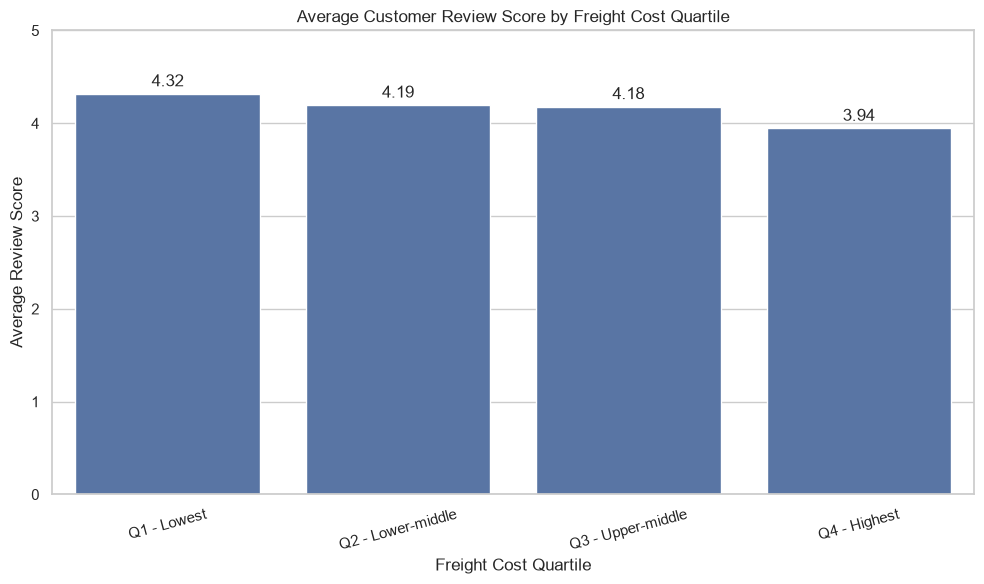

In [11]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=freight_summary,
    x="freight_quartile",
    y="average_review_score"
)

plt.title("Average Customer Review Score by Freight Cost Quartile")
plt.xlabel("Freight Cost Quartile")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.xticks(rotation=15)
plt.tight_layout()

os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/rq3_review_by_freight_quartile.png", dpi=300)
plt.show()

### Freight Costs and Customer Satisfaction

To further explore the relationship between freight costs and customer satisfaction, orders were divided into four approximately equal groups based on their total freight costs. The results revealed a gradual decrease in average customer review scores as freight costs increased. Orders in the lowest freight-cost quartile recorded the highest average review score (M = 4.316), whereas orders in the highest freight-cost quartile recorded the lowest average score (M = 3.944).

The difference between these groups was 0.372 points on the five-point review scale. Although the median review score remained 5 across all four groups, the decreasing mean scores suggest a greater presence or influence of lower ratings among orders with higher freight costs.

These descriptive findings are consistent with the Spearman correlation analysis (ρ = −0.0881, p < .001), which identified a statistically significant but very weak negative association between freight costs and customer satisfaction. Overall, freight costs appear to have a limited association with customer satisfaction, and other aspects of the purchasing and delivery experience are likely to play a more substantial role.